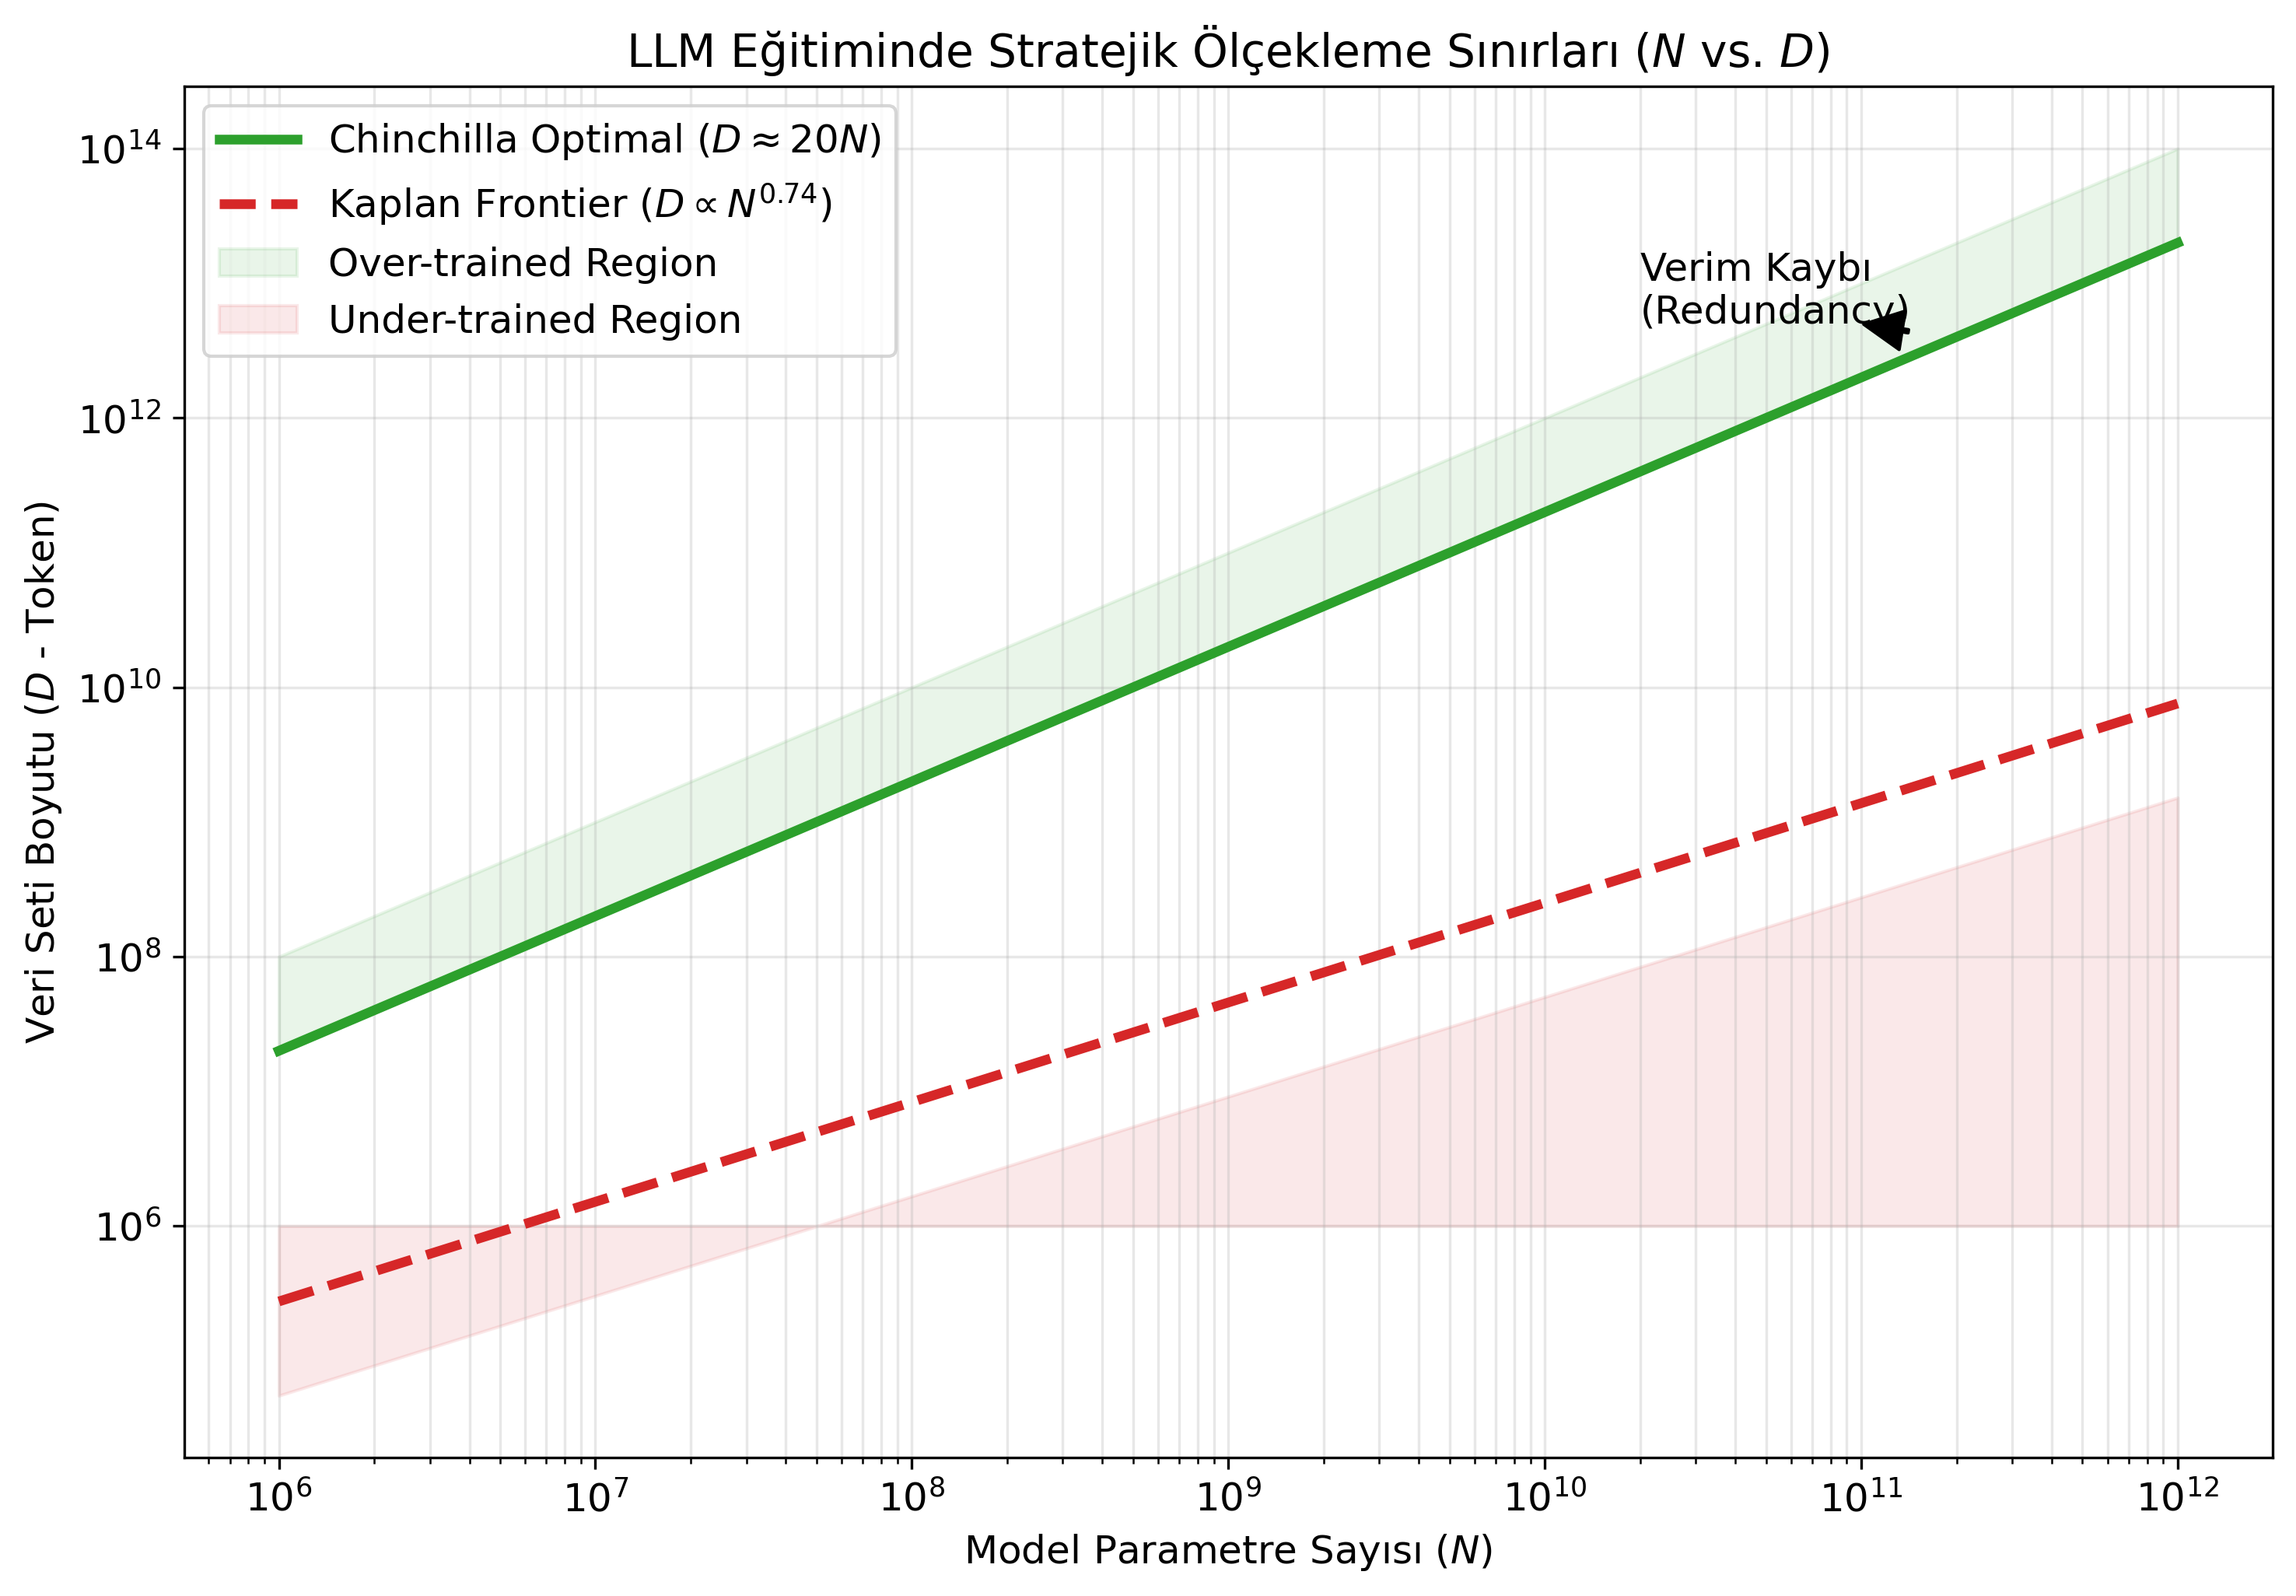

In [4]:
#| label: fig-optimal-frontier
#| fig-cap: "N ve D Arasındaki Optimal Verimlilik Sınırı: Kaplan vs. Chinchilla"
#| echo: true

import numpy as np
import matplotlib.pyplot as plt

# Parametre aralığı (Log ölçeğinde)
N = np.logspace(6, 12, 100) # 1M - 1T parametre

# Kaplan Yasası: D ∝ N^0.74
D_kaplan = 10 * (N**0.74)

# Chinchilla Yasası: D = 20 * N
D_chinchilla = 20 * N

# Grafik Hazırlığı
plt.figure(figsize=(10, 7), dpi=300)

# Optimal Sınırlar - Raw string (r'...') kullanımı hatayı çözer
plt.plot(N, D_chinchilla, label=r'Chinchilla Optimal ($D \approx 20N$)', color='#2ca02c', lw=3)
plt.plot(N, D_kaplan, label=r'Kaplan Frontier ($D \propto N^{0.74}$)', color='#d62728', lw=3, ls='--')

# Azalan Getiri Bölgelerini Boyama
plt.fill_between(N, D_chinchilla, D_chinchilla * 5, color='#2ca02c', alpha=0.1, label='Over-trained Region')
plt.fill_between(N, 1e6, D_kaplan / 5, color='#d62728', alpha=0.1, label='Under-trained Region')

# Ölçeklendirme ve Etiketler
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r"Model Parametre Sayısı ($N$)", fontsize=12)
plt.ylabel(r"Veri Seti Boyutu ($D$ - Token)", fontsize=12)
plt.title(r"LLM Eğitiminde Stratejik Ölçekleme Sınırları ($N$ vs. $D$)", fontsize=14)

# Bilgi Notu - LaTeX uyumlu ok işareti
plt.annotate('Verim Kaybı\n(Redundancy)', xy=(1e11, 5e12), xytext=(2e10, 5e12),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1))

plt.grid(True, which="both", ls="-", alpha=0.3)
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('optimal_frontier.png', dpi=300)
plt.show()